In [12]:
import matplotlib.pyplot as plt

import sys
sys.path.append('../../')

# Import methods
import QGP.Methods as QGP
import NLS_Cubic.Methods as NLS
from QGP.Soliton_Gen import *
from Utilities import norm

i = 1j

# Black soliton errors

In [2]:
L = 20
c = 0 #np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo_GP(x, t):
    return w_soliton(x - c * t)

def black_theo_NLS(x, t):
    black_soliton = lambda x, t: np.exp(-i * t) * w_soliton(x)
    return black_soliton(x - c * t, t)

Creating soliton...
Soliton created


In [6]:
dts = np.array([2**(-j) for j in range(1, 11)])

# Time
tf = 3

# Space
h_1 = 0.05
h_2 = 0.01

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_GP = np.zeros(len(dts))
error_2_GP = np.zeros(len(dts))

error_1_NLS = np.zeros(len(dts))
error_2_NLS = np.zeros(len(dts))

pars_GP = {"k": 0}
pars_NLS = {"k": -1}

ws_1_GP = []
ws_2_GP = []

ws_1_NLS = []
ws_2_NLS = []

# N_1
for dt in dts:
    w_ = QGP.Complex_CNFD(L, N_1, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_1_GP += [w_]
    
    w_ = NLS.CNFD(L, N_1, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_1_NLS += [w_]

# N_2
for dt in dts:
    w_ = QGP.Complex_CNFD(L, N_2, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_2_GP += [w_]
    
    w_ = NLS.CNFD(L, N_2, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_2_NLS += [w_]

In [7]:
# N_1
for j in range(len(dts)):
    w_GP = ws_1_GP[j]
    w_GP.solve()
    
    w_NLS = ws_1_NLS[j]
    w_NLS.solve()

In [8]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_GP[j]
    w_GP.solve()
    
    w_NLS = ws_2_NLS[j]
    w_NLS.solve()

In [9]:
for j in range(len(dts)):
    e_1 = ws_1_GP[j].get_error(tf)
    e_2 = ws_2_GP[j].get_error(tf)
    
    error_1_GP[j] = e_1
    error_2_GP[j] = e_2

In [10]:
for j in range(len(dts)):
    e_1 = ws_1_NLS[j].get_error(tf)
    e_2 = ws_2_NLS[j].get_error(tf)
    
    error_1_NLS[j] = e_1
    error_2_NLS[j] = e_2

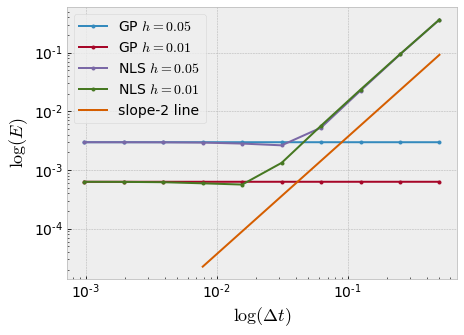

In [21]:
dts_to_plot = dts[:-3]
plt.plot(dts, error_1_GP, ".-", label=r"GP $h=0.05$")
plt.plot(dts, error_2_GP, ".-", label=r"GP $h=0.01$")

plt.plot(dts, error_1_NLS, ".-", label=r"NLS $h=0.05$")
plt.plot(dts, error_2_NLS, ".-", label=r"NLS $h=0.01$")
plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/comp_error_black.png", dpi=300, bbox_inches = "tight")
plt.show()

# Dark soliton errors

In [37]:
L = 20
c = np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo_GP(x, t):
    return w_soliton(x - c * t)

def black_theo_NLS(x, t):
    black_soliton = lambda x, t: np.exp(-i * t) * w_soliton(x)
    return black_soliton(x + c * t, t)

Creating soliton...
Soliton created


In [38]:
dts = np.array([2**(-j) for j in range(1, 11)])

# Time
tf = 3

# Space
h_1 = 0.05
h_2 = 0.01

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_GP = np.zeros(len(dts))
error_2_GP = np.zeros(len(dts))

error_1_NLS = np.zeros(len(dts))
error_2_NLS = np.zeros(len(dts))

pars_GP = {"k": 0}
pars_NLS = {"k": -1}

ws_1_GP = []
ws_2_GP = []

ws_1_NLS = []
ws_2_NLS = []

# N_1
for dt in dts:
    w_ = QGP.Complex_CNFD(L, N_1, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_1_GP += [w_]
    
    w_ = NLS.CNFD(L, N_1, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_1_NLS += [w_]

# N_2
for dt in dts:
    w_ = QGP.Complex_CNFD(L, N_2, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_2_GP += [w_]
    
    w_ = NLS.CNFD(L, N_2, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_2_NLS += [w_]

In [39]:
# N_1
for j in range(len(dts)):
    w_GP = ws_1_GP[j]
    w_GP.solve()
    
    w_NLS = ws_1_NLS[j]
    w_NLS.solve()

In [40]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_GP[j]
    w_GP.solve()
    
    w_NLS = ws_2_NLS[j]
    w_NLS.solve()

In [41]:
for j in range(len(dts)):
    e_1 = ws_1_GP[j].get_error(tf)
    e_2 = ws_2_GP[j].get_error(tf)
    
    error_1_GP[j] = e_1
    error_2_GP[j] = e_2

In [42]:
for j in range(len(dts)):
    e_1 = ws_1_NLS[j].get_error(tf)
    e_2 = ws_2_NLS[j].get_error(tf)
    
    error_1_NLS[j] = e_1
    error_2_NLS[j] = e_2

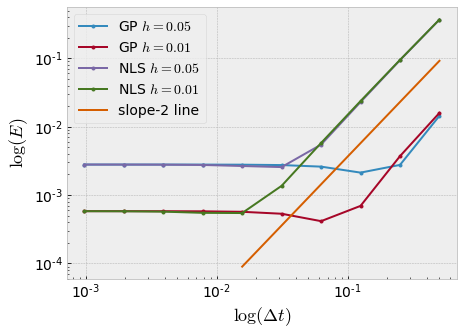

In [46]:
dts_to_plot = dts[:-4]
plt.plot(dts, error_1_GP, ".-", label=r"GP $h=0.05$")
plt.plot(dts, error_2_GP, ".-", label=r"GP $h=0.01$")

plt.plot(dts, error_1_NLS, ".-", label=r"NLS $h=0.05$")
plt.plot(dts, error_2_NLS, ".-", label=r"NLS $h=0.01$")
plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/comp_error_dark.png", dpi=300, bbox_inches = "tight")
plt.show()

## GP Black soliton lower h

In [48]:
L = 20
c = 0 #np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo_GP(x, t):
    return w_soliton(x - c * t)

Creating soliton...
Soliton created


In [61]:
dts = np.array([2**(-j) for j in range(1, 5)])

# Time
tf = 3

# Space
h_1 = 0.005
h_2 = 0.001

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_GP = np.zeros(len(dts))
error_2_GP = np.zeros(len(dts))


pars_GP = {"k": 0}

ws_1_GP = []
ws_2_GP = []


# N_1
for j in range(len(dts)):
    dt = dts[j]
    w_ = QGP.Complex_CNFD(L, N_1, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_1_GP += [w_]

# N_2
for dt in dts:
    w_ = QGP.Complex_CNFD(L, N_2, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_2_GP += [w_]

In [62]:
# N_1
for j in range(len(dts)):
    print("Solving ", j, " of ", len(dts)-1)
    w_GP = ws_1_GP[j]
    w_GP.solve()

Solving  0  of  3


KeyboardInterrupt: 

In [ ]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_GP[j]
    w_GP.solve()

In [ ]:
for j in range(len(dts)):
    e_1 = ws_1_GP[j].get_error(tf)
    e_2 = ws_2_GP[j].get_error(tf)
    
    error_1_GP[j] = e_1
    error_2_GP[j] = e_2

In [ ]:
dts_to_plot = dts[:-4]
plt.plot(dts, error_1_GP, ".-", label=r"GP $h=0.005$")
plt.plot(dts, error_2_GP, ".-", label=r"GP $h=0.001$")

#plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

#plt.savefig("Img/comp_error_dark.png", dpi=300, bbox_inches = "tight")
plt.show()